# 📙 Notebook 10 — Dynamic Monte Carlo Case Study: Choosing the Control Volume
| | |
|---|---|
| ⏱ Time | ~40 min (simulations ≈ 1 min) |
| 🧭 Type | **dynamic Monte Carlo**: Gillespie's method, batch reactor |
| 🎯 Goal | reproduce the control-volume study: event log (**Table 4.2**), polymerization times and dead chains (**Tables 4.2–4.7**), initiator check (**Table 4.9**), w-CLDs (**Figures 4.10–4.11**) |
| 📖 Book | Sec. 4.5–4.6 · Table 4.1 · Algorithm 4.3 |

**The question:** a dynamic simulation follows every molecule in a small **control volume** `V`. How small can `V` be before the results stop representing a bulk reactor? This notebook is about the code; for the discussion, see *Monte Carlo Methods in Polymer Reaction Engineering: From Mechanisms to Molecular Architecture*.

**System:** batch free-radical polymerization of styrene at 90 °C, with the mechanism and rate constants of Case Study 3.1 (Notebook 8): `[M]₀ = 8 mol/L`, `[I]₀ = 0.92 mmol/L`, stop at conversion `X = 0.1`. The code has the same structure as Notebook 6, compiled with Numba (`@njit`) as in Notebooks 8–9.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from numba import njit

## 1 · Parameters
Rate constants from Table 3.2 (min⁻¹, L/(mol·min)).

In [2]:
R_gas, T = 1.987, 90 + 273.15

def arrhenius(A, E):
    return A * np.exp(-E / (R_gas * T))

In [3]:
kd  = arrhenius(1.6945e15, 31500)
kp  = arrhenius(1.302e9,   7759)
ktM = arrhenius(5.14e9,   15230)
ktc = arrhenius(4.92e11,   3470)
ki  = kp

The book doesn't list `k_i` separately. We use fast initiation, `k_i = k_p`, which reproduces the propensities in the first rows of the book's event logs.

In [4]:
NA = 6.022e23
f, M0, I0 = 0.7, 8.0, 0.92e-3
X_target = 0.1

P0 = np.sqrt(f * kd * I0 / ktc)                 # Eq. 4.66
print(f"[P]0 = {P0:.4e} mol/L   (book: 5.468e-09)")

[P]0 = 5.4679e-09 mol/L   (book: 5.468e-09)


## 2 · The state of the control volume
Numba works best with arrays, so the molecule counts go in one small integer array `c`, with a name for each position:

In [5]:
N_M, N_I, N_R, N_P, N_D = 0, 1, 2, 3, 4      # monomer, initiator, primary radicals,
                                             # polymer radicals, dead chains

Two more arrays:
- `P`: the length of every polymer radical; the first `c[N_P]` positions are in use
- `D`: the counting vector of dead chains, `D[n]` = number of dead chains of length `n`

## 3 · One small function per reaction
The same reactions as Notebook 6. First, two helpers: remove a random radical, and record a dead chain.

In [6]:
@njit
def remove_radical(c, P):
    j = np.random.randint(c[N_P])
    length = P[j]
    c[N_P] -= 1
    P[j] = P[c[N_P]]                   # move the last radical into the gap
    return length

In [7]:
@njit
def add_dead(c, D, n):
    if n >= len(D):
        n = len(D) - 1                 # very long chain: keep it in the last slot
    D[n] += 1
    c[N_D] += 1

In [8]:
@njit
def propagation(c, P, D):              # Pn + M → Pn+1
    j = np.random.randint(c[N_P])
    P[j] += 1
    c[N_M] -= 1

In [9]:
@njit
def decomposition(c, P, D):            # I → 2R
    c[N_I] -= 1
    if np.random.random() <= f:
        c[N_R] += 2

In [10]:
@njit
def initiation(c, P, D):               # R + M → P1
    c[N_R] -= 1
    c[N_M] -= 1
    P[c[N_P]] = 1
    c[N_P] += 1

In [11]:
@njit
def transfer(c, P, D):                 # Pn + M → Dn + P1
    j = np.random.randint(c[N_P])
    add_dead(c, D, P[j])
    P[j] = 1
    c[N_M] -= 1

In [12]:
@njit
def combination(c, P, D):              # Pn + Pm → Dn+m
    a = remove_radical(c, P)
    b = remove_radical(c, P)
    add_dead(c, D, a + b)

## 4 · Propensities (Table 4.1) and the roulette wheel
`k` holds the microscopic rate constants in the order of the reaction channels. **Propagation comes first**: it is selected in more than 99 % of the steps, so the roulette wheel usually stops at the first comparison. The order of the channels doesn't change the results, only the speed.

In [13]:
EVENTS = ["Propagation", "Initiator decomposition", "Chain initiation",
          "Transfer to monomer", "Combination"]

In [14]:
@njit
def propensities(c, k, R):
    R[0] = k[0] * c[N_M] * c[N_P]                    # propagation
    R[1] = k[1] * c[N_I]                             # decomposition
    R[2] = k[2] * c[N_R] * c[N_M]                    # initiation
    R[3] = k[3] * c[N_M] * c[N_P]                    # transfer to monomer
    R[4] = k[4] * c[N_P] * (c[N_P] - 1) / 4.0        # combination

In [15]:
@njit
def pick(R, R_total):
    r = np.random.random() * R_total
    cumulative = 0.0
    for j in range(4):
        cumulative += R[j]
        if r < cumulative:
            return j
    return 4

In [16]:
@njit
def execute(j, c, P, D):
    if j == 0:
        propagation(c, P, D)
    elif j == 1:
        decomposition(c, P, D)
    elif j == 2:
        initiation(c, P, D)
    elif j == 3:
        transfer(c, P, D)
    else:
        combination(c, P, D)

## 5 · Setting up a control volume
Convert concentrations to molecule counts and the rate constants to microscopic ones (Table 4.1). `ktc_used` lets us switch combination off later.

In [17]:
def new_system(V, ktc_used):
    VNA = V * NA
    k = np.array([kp / VNA, kd, ki / VNA, ktM / VNA, 2 * ktc_used / VNA])
    c = np.zeros(5, np.int64)
    c[N_M] = round(M0 * VNA)
    c[N_I] = round(I0 * VNA)
    P = np.zeros(2 * c[N_I] + 10, np.int64)
    D = np.zeros(min(int(c[N_M] * X_target) + 10, 3_000_000), np.int64)
    return c, P, D, k

## 6 · The Gillespie loop (Algorithm 4.3)
The same steps as Notebook 6.

One event, start to finish: propensities → roulette wheel → execute → time step. It returns `j = −1` if nothing can react anymore.

In [18]:
@njit
def one_event(c, P, D, k, R):
    propensities(c, k, R)
    R_total = R.sum()
    if R_total <= 0.0:
        return -1, 0.0, 0.0
    j = pick(R, R_total)
    execute(j, c, P, D)
    dt = np.log(1.0 / np.random.random()) / R_total
    return j, dt, R_total

The first events are also written into `log`, one row per event, for the event log:

In [19]:
@njit
def write_log(log, ev, t, dt, R_total, j, c):
    row = log[ev - 1]
    row[0] = ev
    row[1] = t
    row[2] = dt
    row[3] = R_total
    row[4] = j
    for i in range(5):
        row[5 + i] = c[i]

The loop runs events until the target conversion is reached (or nothing can react):

In [20]:
@njit
def gillespie(c, P, D, k, log):
    nM0 = c[N_M]
    R = np.zeros(5)
    t = 0.0
    ev = 0
    while (nM0 - c[N_M]) / nM0 < X_target:
        j, dt, R_total = one_event(c, P, D, k, R)
        if j < 0:
            break
        t += dt
        ev += 1
        if ev <= len(log):
            write_log(log, ev, t, dt, R_total, j, c)
    return t, ev

One function to set everything up and run it:

In [21]:
@njit
def set_seed(seed):
    np.random.seed(seed)

In [22]:
def simulate(V, seed=1, n_log=1, ktc_used=ktc):
    set_seed(seed)
    c, P, D, k = new_system(V, ktc_used)
    nM0 = c[N_M]
    log = np.zeros((n_log, 10))
    t, ev = gillespie(c, P, D, k, log)
    return {"t": t, "events": ev, "X": (nM0 - c[N_M]) / nM0, "c": c, "D": D, "log": log}

## 7 · Event log for V = 10⁻¹⁷ L (compare with Table 4.2)
With so few molecules, every event is visible. The first call compiles the functions, so it takes a few seconds.

In [23]:
run = simulate(1e-17, n_log=8)

log = pd.DataFrame(run["log"], columns=["Reaction", "Time (min)", "Δt (min)", "R_tot (1/min)",
                                        "Event", "n_M", "n_I", "n_R", "n_P", "n_D"])
log["Event"] = [EVENTS[int(j)] for j in log["Event"]]
log = log.astype({"Reaction": int, "n_M": int, "n_I": int, "n_R": int, "n_P": int, "n_D": int})
log

,Reaction,Time (min),Δt (min),R_tot (1/min),Event,n_M,n_I,n_R,n_P,n_D
0,1,8.793244,8.793244e+00,1.032159,Initiator decomposition,48176000,5539,0,0,0
1,2,11.101728,2.308484e+00,1.031973,Initiator decomposition,48176000,5538,2,0,0
2,3,11.101730,2.385158e-06,445499.667335,Chain initiation,48175999,5538,1,1,0
3,4,11.101731,1.387972e-06,445527.687988,Propagation,48175998,5538,1,1,0
4,5,11.101732,8.484682e-07,445527.678741,Propagation,48175997,5538,1,1,0
5,6,11.101733,2.917326e-07,445527.669493,Propagation,48175996,5538,1,1,0
6,7,11.101733,8.973181e-07,445527.660245,Propagation,48175995,5538,1,1,0
7,8,11.101735,1.306677e-06,445527.650997,Propagation,48175994,5538,1,1,0


Compare with the book: `R_tot = 1.03216` at the start (only decomposition is possible), then about `4.455 × 10⁵ min⁻¹` as soon as radicals exist. Nothing happens until the initiator decomposes.

The final state of this run:

In [24]:
print(f"stopped at t = {run['t']:,.0f} min,  conversion X = {run['X']:.4f}")
print(f"initiator left: {run['c'][N_I]},  dead chains: {run['c'][N_D]:,}")

stopped at t = 63,259 min,  conversion X = 0.0524
initiator left: 0,  dead chains: 4,115


The run stops **before** `X = 0.1`: all the initiator was used up. The expected number of radicals in this volume, `n_P = V·[P]·N_A`, is about 0.03, far below 1. Each new pair of radicals is killed almost immediately by combination, so the simulation burns through the initiator (book Sec. 4.6.1).

## 8 · Scanning the control volume
Run five volumes (about a minute in total; the largest takes the longest).

In [25]:
volumes = [1e-17, 2e-17, 5e-17, 1e-16, 5e-16]
scan = {}
for V in volumes:
    scan[V] = simulate(V)
    print(f"V = {V:.0e} L done")

V = 1e-17 L done


V = 2e-17 L done


V = 5e-17 L done


V = 1e-16 L done


V = 5e-16 L done


For each volume: expected `n_P`, final time, conversion reached, dead chains `n_D`, and the initiator check `[I]_MC` vs. `[I]_det = [I]₀·exp(−k_d t)` (Table 4.9). The book's values are added for comparison.

In [26]:
book_t = ["57,241 (stalled)", "19,931", "2,586", "1,280", "508.3"]
book_nD = [4196, 8723, 10667, 14211, 48180]

table = pd.DataFrame(index=[f"{V:.0e} L" for V in volumes])
table["expected n_P"] = [round(V * P0 * NA, 3) for V in volumes]
table["X reached"] = [round(scan[V]["X"], 4) for V in volumes]
table["t_final (min)"] = [round(scan[V]["t"], 1) for V in volumes]
table["book t_final"] = book_t

In [27]:
table["n_D"] = [scan[V]["c"][N_D] for V in volumes]
table["book n_D"] = book_nD
table["[I]_MC"] = [scan[V]["c"][N_I] / (V * NA) for V in volumes]
table["[I]_det"] = [I0 * np.exp(-kd * scan[V]["t"]) for V in volumes]
table

,expected n_P,X reached,t_final (min),book t_final,n_D,book n_D,[I]_MC,[I]_det
1e-17 L,0.033,0.0524,63259.2,"57,241 (stalled)",4115,4196,0.000000,7.002563e-09
2e-17 L,0.066,0.1000,21998.1,"19,931",8782,8723,0.000018,1.527023e-05
5e-17 L,0.165,0.1000,2825.9,"2,586",10838,10667,0.000547,5.434173e-04
1e-16 L,0.329,0.1000,1268.5,"1,280",14201,14211,0.000730,7.263612e-04
5e-16 L,1.646,0.1000,510.7,508.3,47822,48180,0.000837,8.365037e-04


**How to read the table**
- `V = 10⁻¹⁷ L` never reaches `X = 0.1`; its `[I]_MC` drops to zero long before `[I]_det` does.
- The polymerization time keeps changing until `V ≥ 5 × 10⁻¹⁶ L` (`n_P` ≳ 1.6), where it settles near **500 min**.
- `n_D` grows in proportion to `V` once `V` is large enough, as it should.
- Each run is random: small volumes scatter more from run to run (try another `seed`).

### Optional: one larger volume
`V = 10⁻¹⁵ L` takes about 1.5 minutes. The book gives `t_final = 501.9 min` and `n_D = 95,231`. Change `False` to `True` to run it; it is then added to the figures below.

In [28]:
RUN_LARGER = False
if RUN_LARGER:
    scan[1e-15] = simulate(1e-15)
    print(f"t_final = {scan[1e-15]['t']:.1f} min,  n_D = {scan[1e-15]['c'][N_D]:,}")

## 9 · Figures 4.10 and 4.11: w-CLDs vs. control volume
Bin size `Δn = 100`, as in the book.

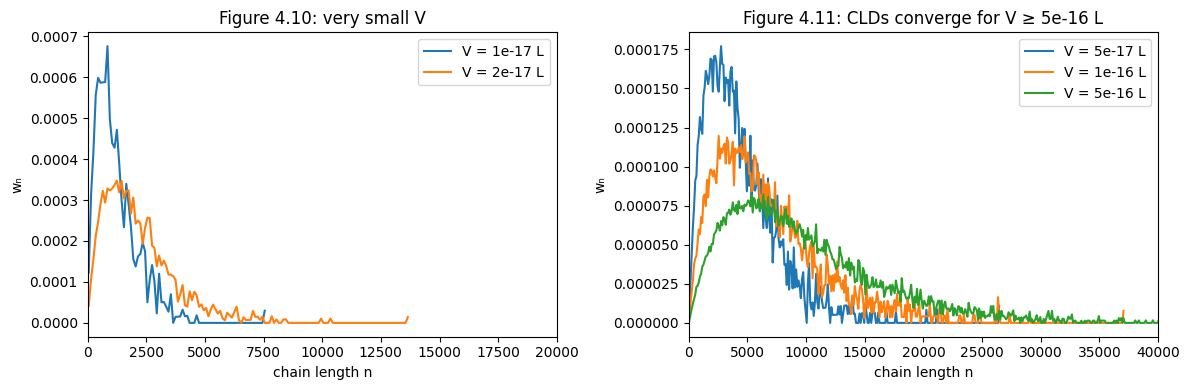

In [29]:
#@title Plot Figures 4.10 and 4.11
def wcld(D, dn=100):
    nn = np.arange(len(D)); last = np.nonzero(D)[0].max()
    edges = np.arange(1, last + dn, dn); mass, _ = np.histogram(nn, bins=edges, weights=nn*D)
    return 0.5*(edges[1:] + edges[:-1]), mass / mass.sum() / dn
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for V in [1e-17, 2e-17]:
    x, w = wcld(scan[V]["D"]); ax[0].plot(x, w, label=f"V = {V:.0e} L")
ax[0].set_title("Figure 4.10: very small V"); ax[0].set_xlim(0, 20_000)
for V in [5e-17, 1e-16, 5e-16, 1e-15]:
    if V in scan:
        x, w = wcld(scan[V]["D"]); ax[1].plot(x, w, label=f"V = {V:.0e} L")
ax[1].set_title("Figure 4.11: CLDs converge for V ≥ 5e-16 L"); ax[1].set_xlim(0, 40_000)
for a in ax: a.set_xlabel("chain length n"); a.set_ylabel("wₙ"); a.legend()
plt.tight_layout(); plt.show()

## ✅ What the code taught us
- In dynamic Monte Carlo, the **control volume is a model parameter**: too small, and the simulation becomes a "nanoreactor" with too few radicals.
- Practical rule (book Sec. 4.6): choose `V` so that `n_P = V·[P]·N_A` is well above 1, preferably tens.
- Checks: the CLD, the polymerization time, and the initiator decay should all become **independent of V**. The initiator check alone is necessary but not sufficient.
- The book shows full convergence at `V ≥ 10⁻¹⁴ L` (~5 × 10⁹ events per run, too long for a quick notebook; see Table 4.8).

### 🧪 Try it yourself
1. Re-run the scan with `simulate(V, seed=2)`. Which volumes change the most?
2. Run the optional `10⁻¹⁵ L` cell. How close is `t_final` to the 5 × 10⁻¹⁶ L result?
3. Remove combination with `simulate(1e-17, ktc_used=0)` (book Sec. 4.6.3). Does the run reach `X = 0.1` now? What happens to `n_P`?